# 叶片病害分割 + 多物种/多疾病识别

## 1. 配置

In [2]:
import random
import re
from pathlib import Path

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import segmentation_models_pytorch as smp
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from albumentations.pytorch import ToTensorV2
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm import tqdm

plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# ---------------------------------------------------------------- 路径
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "train" else Path.cwd()
DATA_ROOT = PROJECT_ROOT / "Leaf Disease Segment"
SEG_DIR = DATA_ROOT / "segment"            # {split}/images + {split}/masks
CLS_DIR = DATA_ROOT / "classification"     # {split}/{类别名}/*.jpg
CLS_EXTRA_DIR = DATA_ROOT / "classification_extra"   # 只补训练集: train/{类别名}/*.jpg
MODELS_DIR = PROJECT_ROOT / "models"
RUNS_DIR = PROJECT_ROOT / "train" / "runs" / "leaf_disease"
SEG_CKPT = MODELS_DIR / "leaf_disease_segment_model.pth"
CLS_CKPT = MODELS_DIR / "leaf_disease_classify_model.pth"
for path in (MODELS_DIR, RUNS_DIR):
    path.mkdir(parents=True, exist_ok=True)

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------------------------------------------------------- 分割参数
SEG_SIZE = 512          # 输入边长
SEG_BATCH = 4
SEG_EPOCHS = 50
SEG_LR = 1e-4
SEG_PATIENCE = 10
SEG_BCE_W, SEG_DICE_W = 0.5, 1.0

CLS_BACKBONE = "vit_small_patch14_dinov2.lvd142m"
CLS_UNFREEZE_BLOCKS = 4
CLS_TTA = True             # 验证/测试时原图 + 水平翻转取平均
CLS_HIDDEN = 256
CLS_DROPOUT = 0.3
CLS_EPOCHS = 50
CLS_PATIENCE = 10
CLS_BATCH = 8
CLS_ACCUM = 2              # 有效 batch 16
CLS_LR = 5e-4              # 分类头
CLS_BACKBONE_LR = 5e-5
CLS_WARMUP_EPOCHS = 2
CLS_WEIGHT_DECAY = 0.02
CLS_LABEL_SMOOTHING = 0.1

assert SEG_DIR.is_dir(), f"找不到分割目录: {SEG_DIR}"
assert CLS_DIR.is_dir(), f"找不到分类目录: {CLS_DIR}"
print("项目根目录:", PROJECT_ROOT)
print("设备:", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print(f"分割: {SEG_SIZE}px / batch {SEG_BATCH} / {SEG_EPOCHS} 轮")
print(f"分类: {CLS_BACKBONE} 微调最后 {CLS_UNFREEZE_BLOCKS} 个 block")

项目根目录: D:\WorkSpace2\plants-intelligent-system
设备: cuda | NVIDIA GeForce RTX 4060 Laptop GPU
分割: 512px / batch 4 / 50 轮
分类: vit_small_patch14_dinov2.lvd142m 微调最后 4 个 block


## 2. 分割数据集

In [3]:
def collect_seg_pairs():
    """扫描 segment/{split}/{images,masks}，按文件名主干配对（图是 .jpg，mask 是 .png）。"""
    pairs = {}
    for split in ("train", "val", "test"):
        image_dir = SEG_DIR / split / "images"
        mask_dir = SEG_DIR / split / "masks"
        items = []
        for image_path in sorted(image_dir.iterdir()):
            if image_path.suffix.lower() not in IMAGE_EXTS:
                continue
            mask_path = next(
                (mask_dir / f"{image_path.stem}{suffix}" for suffix in (".png", ".jpg")
                 if (mask_dir / f"{image_path.stem}{suffix}").exists()), None)
            if mask_path is not None:
                items.append((image_path, mask_path))
        pairs[split] = items
    return pairs


seg_pairs = collect_seg_pairs()
assert all(seg_pairs.values()), "有 split 读不到图片"
print("分割对数:", {k: len(v) for k, v in seg_pairs.items()},
      "| 合计", sum(len(v) for v in seg_pairs.values()))


def seg_transforms(size):
    """训练要有几何/亮度增强；验证测试只做 resize。mask 跟着一起变换。"""
    train_tf = A.Compose([
        A.Resize(size, size),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.3),
        A.RandomRotate90(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=20, p=0.5),
        A.RandomBrightnessContrast(p=0.4),
        A.Normalize(),
        ToTensorV2(),
    ])
    eval_tf = A.Compose([A.Resize(size, size), A.Normalize(), ToTensorV2()])
    return train_tf, eval_tf


SEG_TRAIN_TF, SEG_EVAL_TF = seg_transforms(SEG_SIZE)


class SegmentDataset(Dataset):
    def __init__(self, pairs, transform):
        self.pairs = pairs
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]
        image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        out = self.transform(image=image, mask=mask)
        return out["image"], (out["mask"] > 0).float().unsqueeze(0)


seg_loaders = {
    "train": DataLoader(SegmentDataset(seg_pairs["train"], SEG_TRAIN_TF),
                        batch_size=SEG_BATCH, shuffle=True, drop_last=True, pin_memory=True),
    "val": DataLoader(SegmentDataset(seg_pairs["val"], SEG_EVAL_TF),
                      batch_size=SEG_BATCH, shuffle=False, pin_memory=True),
    "test": DataLoader(SegmentDataset(seg_pairs["test"], SEG_EVAL_TF),
                       batch_size=SEG_BATCH, shuffle=False, pin_memory=True),
}
print("分割 batch 数:", {k: len(v) for k, v in seg_loaders.items()})

分割对数: {'train': 414, 'val': 87, 'test': 87} | 合计 588
分割 batch 数: {'train': 103, 'val': 22, 'test': 22}


D:\WorkSpace\MiniConda\envs\myenv\lib\site-packages\albumentations\core\validation.py:87: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


## 3. 分割样本

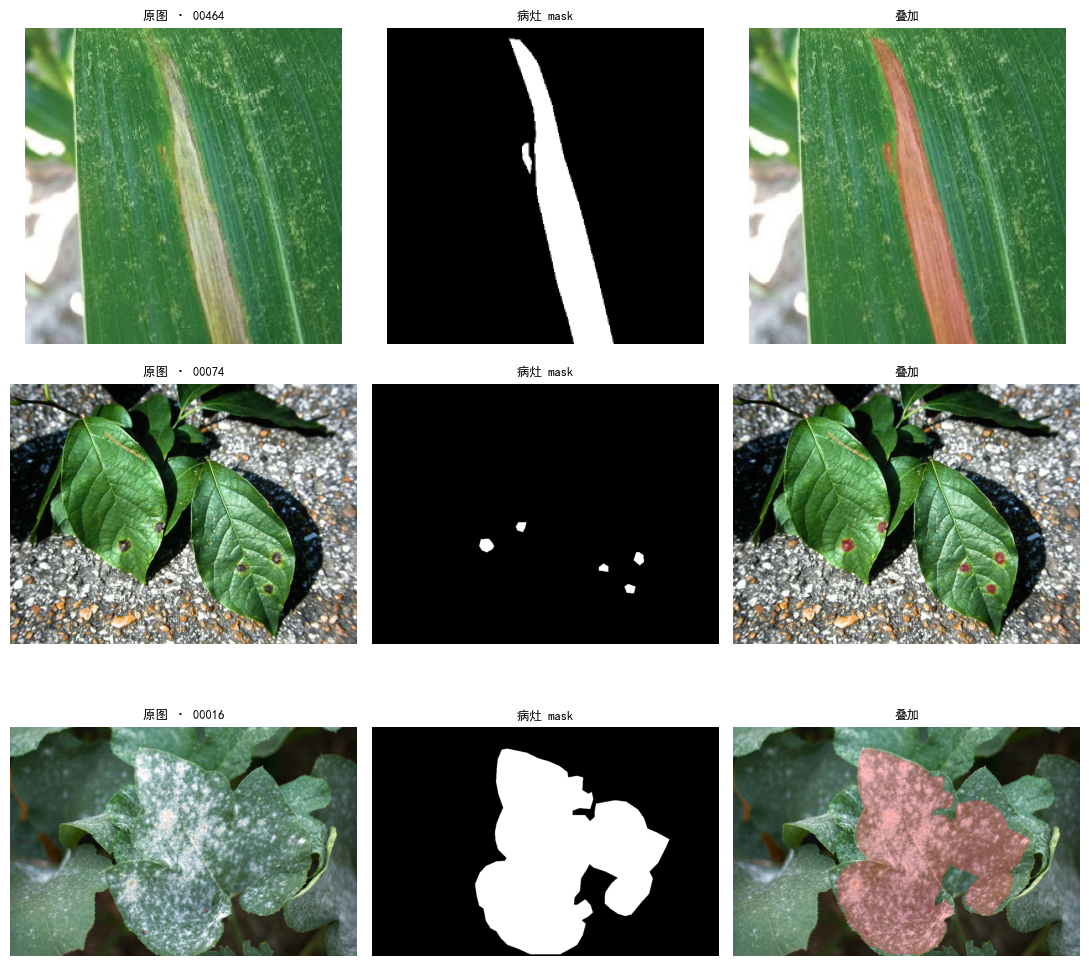

In [4]:
samples = random.sample(seg_pairs["train"], min(3, len(seg_pairs["train"])))
fig, axes = plt.subplots(len(samples), 3, figsize=(11, 3.4 * len(samples)))
axes = np.atleast_2d(axes)

for row, (image_path, mask_path) in enumerate(samples):
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    overlay = image.copy()
    overlay[mask > 0] = [255, 66, 66]
    overlay = cv2.addWeighted(image, 0.65, overlay, 0.35, 0)

    axes[row, 0].imshow(image); axes[row, 0].set_title(f"原图 · {image_path.stem}", fontsize=9)
    axes[row, 1].imshow(mask, cmap="gray"); axes[row, 1].set_title("病灶 mask", fontsize=9)
    axes[row, 2].imshow(overlay); axes[row, 2].set_title("叠加", fontsize=9)
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## 4. 分割模型训练

In [5]:
seg_model = smp.UnetPlusPlus(
    encoder_name="efficientnet-b0",
    encoder_weights=None,      # 下面手动加载本地权重，避免联网卡住
    in_channels=3,
    classes=1,
).to(DEVICE)

B0_CACHE = Path.home() / ".cache" / "torch" / "hub" / "checkpoints" / "efficientnet-b0-355c32eb.pth"
if B0_CACHE.exists():
    seg_model.encoder.load_state_dict(torch.load(B0_CACHE, map_location="cpu"), strict=False)
    print("已加载本地 EfficientNet-B0 ImageNet 权重")
else:
    print("没找到本地 ImageNet 权重，encoder 从零训练")

bce_loss = nn.BCEWithLogitsLoss()
dice_loss = smp.losses.DiceLoss(mode="binary", from_logits=True)


def seg_criterion(logits, masks):
    return SEG_BCE_W * bce_loss(logits, masks) + SEG_DICE_W * dice_loss(logits, masks)


def dice_score(logits, masks):
    """一个 batch 的 Dice，用于验证集。"""
    pred = (torch.sigmoid(logits) > 0.5).float()
    target = (masks > 0.5).float()
    intersection = (pred * target).sum()
    return float((2 * intersection + 1e-7) / (pred.sum() + target.sum() + 1e-7))


seg_optimizer = torch.optim.AdamW(seg_model.parameters(), lr=SEG_LR, weight_decay=1e-4)
seg_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    seg_optimizer, mode="max", factor=0.5, patience=3)
seg_amp = DEVICE.type == "cuda"
seg_scaler = torch.cuda.amp.GradScaler(enabled=seg_amp)

seg_history = {"train_loss": [], "val_loss": [], "val_dice": []}
best_dice, bad_epochs = 0.0, 0

for epoch in range(1, SEG_EPOCHS + 1):
    seg_model.train()
    train_loss = 0.0
    for images, masks in tqdm(seg_loaders["train"], desc=f"分割训练 {epoch:02d}/{SEG_EPOCHS}",
                              leave=False, dynamic_ncols=True):
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        with torch.cuda.amp.autocast(enabled=seg_amp):
            loss = seg_criterion(seg_model(images), masks)
        seg_optimizer.zero_grad(set_to_none=True)
        seg_scaler.scale(loss).backward()
        seg_scaler.step(seg_optimizer)
        seg_scaler.update()
        train_loss += loss.item() * images.size(0)

    seg_model.eval()
    val_loss, val_dice = 0.0, 0.0
    with torch.no_grad(), torch.cuda.amp.autocast(enabled=seg_amp):
        for images, masks in seg_loaders["val"]:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            logits = seg_model(images)
            val_loss += seg_criterion(logits, masks).item() * images.size(0)
            val_dice += dice_score(logits, masks) * images.size(0)

    train_loss /= len(seg_pairs["train"])
    val_loss /= len(seg_pairs["val"])
    val_dice /= len(seg_pairs["val"])
    seg_scheduler.step(val_dice)

    seg_history["train_loss"].append(train_loss)
    seg_history["val_loss"].append(val_loss)
    seg_history["val_dice"].append(val_dice)
    print(f"epoch {epoch:02d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
          f"val dice {val_dice:.4f} | lr {seg_optimizer.param_groups[0]['lr']:.1e}")

    if val_dice > best_dice + 1e-4:
        best_dice, bad_epochs = val_dice, 0
        torch.save({
            "model_state_dict": seg_model.state_dict(),
            "epoch": epoch,
            "best_dice": best_dice,
            "config": {"architecture": "UnetPlusPlus", "encoder": "efficientnet-b0",
                       "img_size": SEG_SIZE, "classes": 1},
        }, SEG_CKPT)
    else:
        bad_epochs += 1
        if bad_epochs >= SEG_PATIENCE:
            print(f"早停：第 {epoch} 轮，最好 dice {best_dice:.4f}")
            break

print("best dice:", round(best_dice, 4))
print("已保存:", SEG_CKPT)

已加载本地 EfficientNet-B0 ImageNet 权重


epoch 01 | train loss 1.0191 | val loss 0.7998 | val dice 0.6733 | lr 1.0e-04


epoch 02 | train loss 0.7636 | val loss 0.6222 | val dice 0.7535 | lr 1.0e-04


epoch 03 | train loss 0.6199 | val loss 0.5283 | val dice 0.7657 | lr 1.0e-04


epoch 04 | train loss 0.5301 | val loss 0.4903 | val dice 0.7573 | lr 1.0e-04


epoch 05 | train loss 0.4722 | val loss 0.4133 | val dice 0.7890 | lr 1.0e-04


... (28 outputs left out)

epoch 34 | train loss 0.1938 | val loss 0.2861 | val dice 0.8232 | lr 1.3e-05


epoch 35 | train loss 0.1984 | val loss 0.3008 | val dice 0.8130 | lr 6.3e-06


epoch 36 | train loss 0.1923 | val loss 0.2913 | val dice 0.8186 | lr 6.3e-06


epoch 37 | train loss 0.1932 | val loss 0.2886 | val dice 0.8205 | lr 6.3e-06
早停：第 37 轮，最好 dice 0.8233
best dice: 0.8233
已保存: D:\WorkSpace2\plants-intelligent-system\models\leaf_disease_segment_model.pth


## 5. 分割评估（测试集）

整体 Dice 0.8492 | 整体 IoU 0.7380
逐张 Dice: 均值 0.7955 | 中位 0.8479 | 最低 0.1480（空 mask 图 0 张）


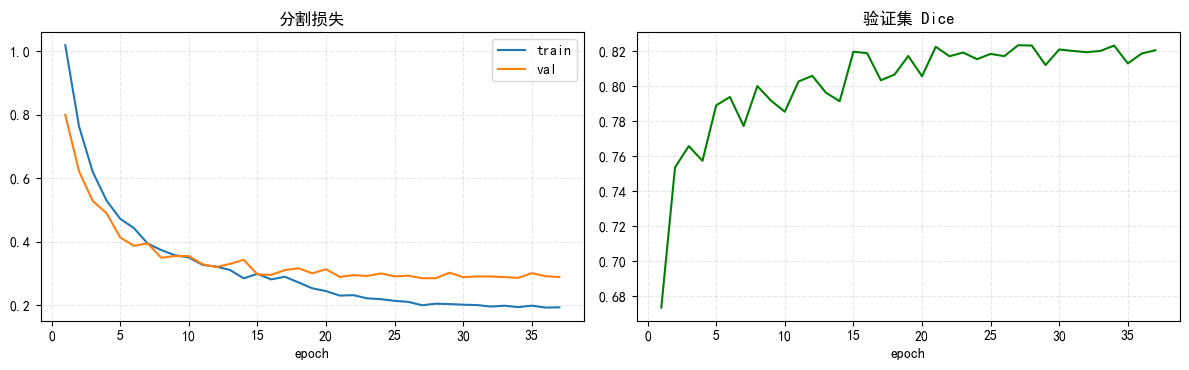

In [6]:
seg_payload = torch.load(SEG_CKPT, map_location=DEVICE)
seg_model.load_state_dict(seg_payload["model_state_dict"])
seg_model.eval()

intersection = union = pred_sum = target_sum = 0.0
per_image = []
with torch.no_grad():
    for images, masks in seg_loaders["test"]:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        pred = (torch.sigmoid(seg_model(images)) > 0.5).float()
        target = (masks > 0.5).float()
        intersection += (pred * target).sum().item()
        union += ((pred + target) > 0).sum().item()
        pred_sum += pred.sum().item()
        target_sum += target.sum().item()
        for i in range(images.size(0)):
            p, t = pred[i], target[i]
            denom = float(p.sum() + t.sum())
            per_image.append(2 * float((p * t).sum()) / denom if denom > 0 else float("nan"))

test_dice = (2 * intersection + 1e-7) / (pred_sum + target_sum + 1e-7)
test_iou = (intersection + 1e-7) / (union + 1e-7)
per_image = np.array(per_image)
valid = per_image[~np.isnan(per_image)]

print(f"整体 Dice {test_dice:.4f} | 整体 IoU {test_iou:.4f}")
print(f"逐张 Dice: 均值 {valid.mean():.4f} | 中位 {np.median(valid):.4f} | "
      f"最低 {valid.min():.4f}（空 mask 图 {int(np.isnan(per_image).sum())} 张）")

epochs = np.arange(1, len(seg_history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(epochs, seg_history["train_loss"], label="train")
axes[0].plot(epochs, seg_history["val_loss"], label="val")
axes[0].set_title("分割损失"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(epochs, seg_history["val_dice"], color="green")
axes[1].set_title("验证集 Dice"); axes[1].set_xlabel("epoch")
for ax in axes:
    ax.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

## 6. 分类数据

In [8]:
LABEL_MAP = {
    "Corn_Gray_leaf_spot": ("Corn", "Gray leaf spot"),
    "Corn_Leaf_blight": ("Corn", "Leaf blight"),
    "Corn_Rust": ("Corn", "Rust"),
    "Grape_Black_rot": ("Grape", "Black rot"),
    "Potato_Early_blight": ("Potato", "Early blight"),
    "Potato_Late_blight": ("Potato", "Late blight"),
    "Squash_Powdery_mildew": ("Squash", "Powdery mildew"),
    "Tomato_Bacterial_spot": ("Tomato", "Bacterial spot"),
    "Tomato_Early_blight": ("Tomato", "Early blight"),
    "Tomato_Late_blight": ("Tomato", "Late blight"),
    "Tomato_Leaf_mold": ("Tomato", "Leaf mold"),
    "Tomato_Septoria_leaf_spot": ("Tomato", "Septoria leaf spot"),
}


def collect_cls_frame():
    rows = []
    for split in ("train", "val", "test"):
        for label_dir in sorted((CLS_DIR / split).iterdir()):
            if not label_dir.is_dir() or label_dir.name not in LABEL_MAP:
                continue
            species, disease = LABEL_MAP[label_dir.name]
            for image_path in sorted(label_dir.iterdir()):
                if image_path.suffix.lower() not in IMAGE_EXTS:
                    continue
                if re.search(r"_\d+$", image_path.stem):     # 离线增强副本
                    continue
                rows.append({"path": str(image_path), "label": f"{species} - {disease}",
                             "species": species, "disease": disease, "split": split})
    # 补充训练集：PlantDoc 里原来没用上的 829 张（只进 train，绝不进 val/test）
    if CLS_EXTRA_DIR.is_dir():
        for label_dir in sorted((CLS_EXTRA_DIR / "train").iterdir()):
            if not label_dir.is_dir() or label_dir.name not in LABEL_MAP:
                continue
            species, disease = LABEL_MAP[label_dir.name]
            for image_path in sorted(label_dir.iterdir()):
                if image_path.suffix.lower() not in IMAGE_EXTS:
                    continue
                rows.append({"path": str(image_path), "label": f"{species} - {disease}",
                             "species": species, "disease": disease, "split": "train"})
    return pd.DataFrame(rows)


cls_df = collect_cls_frame()
assert len(cls_df), "分类目录里没读到图片"
species_names = sorted(cls_df["species"].unique())
disease_names = sorted(cls_df["disease"].unique())
species_to_diseases = {
    sp: sorted(cls_df.loc[cls_df["species"] == sp, "disease"].unique()) for sp in species_names
}
cls_df["species_idx"] = cls_df["species"].map({n: i for i, n in enumerate(species_names)})
cls_df["disease_idx"] = cls_df["disease"].map({n: i for i, n in enumerate(disease_names)})

print("物种:", species_names)
print("疾病:", disease_names)
print("划分:", cls_df["split"].value_counts().to_dict())
print(cls_df.groupby("label")["split"].value_counts().unstack(fill_value=0))

物种: ['Corn', 'Grape', 'Potato', 'Squash', 'Tomato']
疾病: ['Bacterial spot', 'Black rot', 'Early blight', 'Gray leaf spot', 'Late blight', 'Leaf blight', 'Leaf mold', 'Powdery mildew', 'Rust', 'Septoria leaf spot']
划分: {'train': 1232, 'val': 87, 'test': 87}
split                        test  train  val
label                                        
Corn - Gray leaf spot           6     57    6
Corn - Leaf blight             15    161   15
Corn - Rust                     5    106    5
Grape - Black rot               4     69    4
Potato - Early blight          10    128   11
Potato - Late blight            7     89    7
Squash - Powdery mildew         4    117    4
Tomato - Bacterial spot         8    103    8
Tomato - Early blight           5     76    4
Tomato - Late blight           11    107   11
Tomato - Leaf mold              7     81    7
Tomato - Septoria leaf spot     5    138    5


## 7. 分类样本（每个物种抽 2 张）

C:\Users\98470\AppData\Local\Temp\ipykernel_17812\1493060656.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  samples = cls_df.groupby("species", group_keys=False).apply(


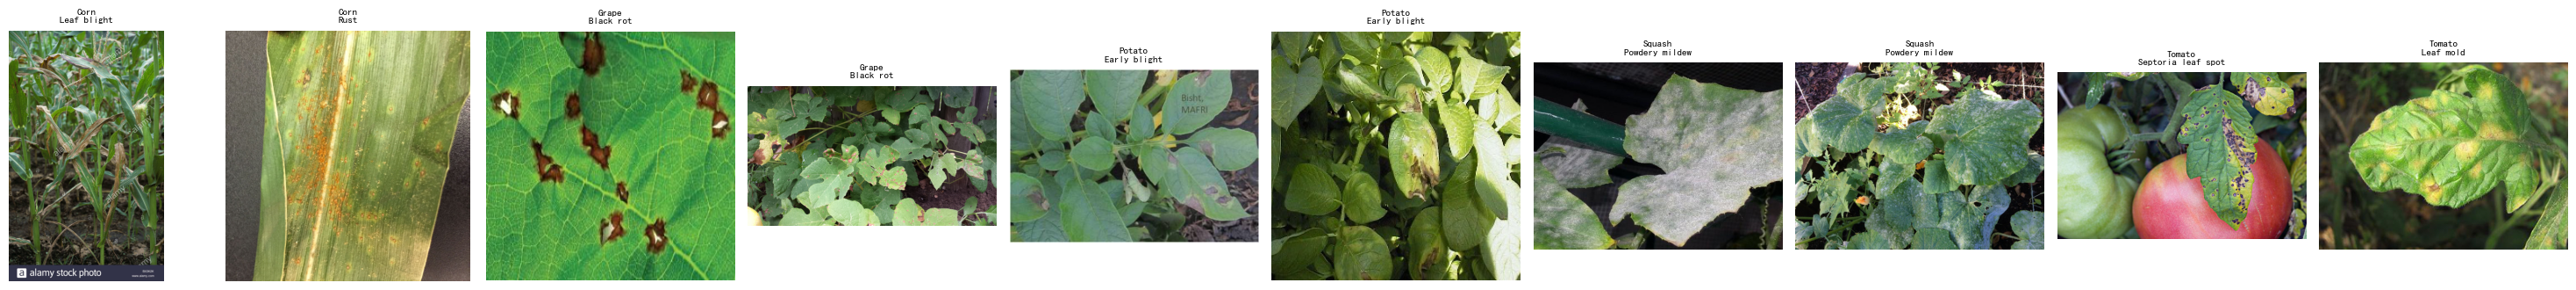

In [9]:
samples = cls_df.groupby("species", group_keys=False).apply(
    lambda group: group.sample(n=min(2, len(group)), random_state=SEED))
samples = samples.reset_index(drop=True)

fig, axes = plt.subplots(1, len(samples), figsize=(3 * len(samples), 3.4))
axes = np.atleast_1d(axes)
for ax, (_, row) in zip(axes, samples.iterrows()):
    ax.imshow(Image.open(row["path"]).convert("RGB"))
    ax.set_title(f'{row["species"]}\n{row["disease"]}', fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. 分类模型（DINOv2 微调最后 4 个 block + 分类头）

In [10]:
class LeafClassifier(nn.Module):
    """DINOv2 主干（只放开最后 N 个 block）+ 两路分类头。"""

    def __init__(self, backbone_name, n_species, n_diseases, hidden=256, dropout=0.3,
                 unfreeze_blocks=4):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=True, num_classes=0)
        for param in self.backbone.parameters():
            param.requires_grad_(False)
        for block in self.backbone.blocks[-unfreeze_blocks:]:
            for param in block.parameters():
                param.requires_grad_(True)
        if hasattr(self.backbone, "norm"):
            for param in self.backbone.norm.parameters():
                param.requires_grad_(True)
        self.unfreeze_blocks = unfreeze_blocks

        in_dim = self.backbone.num_features
        self.head = nn.Sequential(
            nn.LayerNorm(in_dim),
            nn.Linear(in_dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.species = nn.Linear(hidden, n_species)
        self.disease = nn.Linear(hidden, n_diseases)

    def forward(self, images):
        hidden = self.head(self.backbone(images))
        return self.species(hidden), self.disease(hidden)


cls_model = LeafClassifier(
    CLS_BACKBONE, len(species_names), len(disease_names),
    hidden=CLS_HIDDEN, dropout=CLS_DROPOUT, unfreeze_blocks=CLS_UNFREEZE_BLOCKS,
).to(DEVICE)

data_cfg = timm.data.resolve_data_config(cls_model.backbone.pretrained_cfg, model=cls_model.backbone)
CLS_IMG_SIZE = data_cfg["input_size"][-1]
trainable = sum(p.numel() for p in cls_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in cls_model.parameters())
print(f"主干 {CLS_BACKBONE} | 输入 {CLS_IMG_SIZE}px | 放开最后 {CLS_UNFREEZE_BLOCKS} 个 block")
print(f"可训练参数 {trainable:,} / 总参数 {total:,}（{trainable / total:.0%}）")


class ClsDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame["path"].tolist()
        self.species = frame["species_idx"].tolist()
        self.diseases = frame["disease_idx"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image = Image.open(self.paths[index]).convert("RGB")
        return self.transform(image), self.species[index], self.diseases[index]


cls_train_tf = transforms.Compose([
    transforms.RandomResizedCrop(CLS_IMG_SIZE, scale=(0.55, 1.0), ratio=(0.8, 1.25)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.25, 0.25, 0.2, 0.03),
    transforms.ToTensor(),
    transforms.Normalize(mean=data_cfg["mean"], std=data_cfg["std"]),
])
cls_eval_tf = transforms.Compose([
    transforms.Resize(CLS_IMG_SIZE),
    transforms.CenterCrop(CLS_IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=data_cfg["mean"], std=data_cfg["std"]),
])

cls_loaders = {
    split: DataLoader(
        ClsDataset(cls_df[cls_df["split"] == split],
                   cls_train_tf if split == "train" else cls_eval_tf),
        batch_size=CLS_BATCH,
        shuffle=(split == "train"),
        num_workers=0,
        pin_memory=True,
        drop_last=(split == "train"),
    )
    for split in ("train", "val", "test")
}
print({name: len(loader.dataset) for name, loader in cls_loaders.items()})

主干 vit_small_patch14_dinov2.lvd142m | 输入 518px | 放开最后 4 个 block
可训练参数 7,204,879 / 总参数 22,159,375（33%）
{'train': 1232, 'val': 87, 'test': 87}


## 9. 分类训练

主干可训参数 7,101,696 | 头 103,183


epoch 01/50 | train 1.1430 | val 0.6307 | 物种 0.9310 | 疾病 0.6782 | 均值 0.8046 | lr 5.0e-04 | 82s  ← best


epoch 02/50 | train 0.8378 | val 0.6301 | 物种 0.8621 | 疾病 0.7011 | 均值 0.7816 | lr 5.0e-04 | 77s


epoch 03/50 | train 0.7524 | val 0.6449 | 物种 0.8506 | 疾病 0.7471 | 均值 0.7989 | lr 5.0e-04 | 76s


epoch 04/50 | train 0.7062 | val 0.4535 | 物种 0.9310 | 疾病 0.7586 | 均值 0.8448 | lr 5.0e-04 | 75s  ← best


epoch 05/50 | train 0.6770 | val 0.5051 | 物种 0.9310 | 疾病 0.7471 | 均值 0.8391 | lr 5.0e-04 | 75s


... (16 outputs left out)

epoch 22/50 | train 0.4746 | val 0.4574 | 物种 0.9310 | 疾病 0.8046 | 均值 0.8678 | lr 3.2e-04 | 72s


epoch 23/50 | train 0.4618 | val 0.4277 | 物种 0.9540 | 疾病 0.8391 | 均值 0.8966 | lr 3.0e-04 | 72s


epoch 24/50 | train 0.4619 | val 0.5210 | 物种 0.9425 | 疾病 0.8046 | 均值 0.8736 | lr 2.9e-04 | 73s


epoch 25/50 | train 0.4630 | val 0.4348 | 物种 0.9655 | 疾病 0.8161 | 均值 0.8908 | lr 2.7e-04 | 75s
早停：第 25 轮（best epoch 15, score 0.9023）
best score 0.9023 @ epoch 15
已保存: D:\WorkSpace2\plants-intelligent-system\models\leaf_disease_classify_model.pth


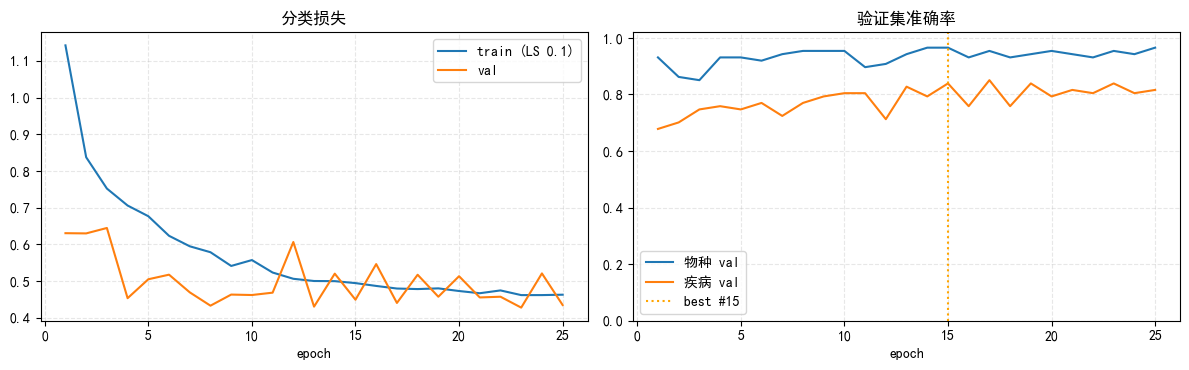

In [11]:
import math
import time

cls_amp = DEVICE.type == "cuda"
cls_scaler = torch.cuda.amp.GradScaler(enabled=cls_amp)
train_loss_fn = nn.CrossEntropyLoss(label_smoothing=CLS_LABEL_SMOOTHING)
report_loss_fn = nn.CrossEntropyLoss()

backbone_params = [p for p in cls_model.backbone.parameters() if p.requires_grad]
head_params = [p for name, p in cls_model.named_parameters() if not name.startswith("backbone.")]
cls_optimizer = torch.optim.AdamW([
    {"params": backbone_params, "lr": CLS_BACKBONE_LR},
    {"params": head_params, "lr": CLS_LR},
], weight_decay=CLS_WEIGHT_DECAY)
print(f"主干可训参数 {sum(p.numel() for p in backbone_params):,} | "
      f"头 {sum(p.numel() for p in head_params):,}")


def lr_factor(epoch_index):
    """2 轮 warmup + cosine，主干和头按各自 base lr 等比缩放。"""
    if epoch_index < CLS_WARMUP_EPOCHS:
        return (epoch_index + 1) / max(1, CLS_WARMUP_EPOCHS)
    progress = (epoch_index - CLS_WARMUP_EPOCHS) / max(1, CLS_EPOCHS - CLS_WARMUP_EPOCHS)
    return 0.02 + 0.98 * 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))


cls_scheduler = torch.optim.lr_scheduler.LambdaLR(cls_optimizer, lr_factor)


def run_epoch(loader, train, desc):
    cls_model.train() if train else cls_model.eval()
    loss_sum, total, species_ok, disease_ok = 0.0, 0, 0, 0
    steps = len(loader)
    if train:
        cls_optimizer.zero_grad(set_to_none=True)

    bar = tqdm(loader, desc=desc, leave=False, dynamic_ncols=True)
    for step, (images, species, diseases) in enumerate(bar, 1):
        images = images.to(DEVICE, non_blocking=True)
        species = species.to(DEVICE, non_blocking=True)
        diseases = diseases.to(DEVICE, non_blocking=True)

        with torch.set_grad_enabled(train):
            with torch.cuda.amp.autocast(enabled=cls_amp):
                logits_species, logits_disease = cls_model(images)
                loss = (train_loss_fn(logits_species, species)
                        + train_loss_fn(logits_disease, diseases)) / 2

            if train:
                cls_scaler.scale(loss / CLS_ACCUM).backward()
                if step % CLS_ACCUM == 0 or step == steps:
                    cls_scaler.unscale_(cls_optimizer)
                    torch.nn.utils.clip_grad_norm_(cls_model.parameters(), 1.0)
                    cls_scaler.step(cls_optimizer)
                    cls_scaler.update()
                    cls_optimizer.zero_grad(set_to_none=True)

        batch = images.size(0)
        loss_sum += loss.item() * batch
        species_ok += (logits_species.argmax(1) == species).sum().item()
        disease_ok += (logits_disease.argmax(1) == diseases).sum().item()
        total += batch
        bar.set_postfix({"loss": f"{loss_sum / total:.3f}",
                         "物种": f"{species_ok / total:.3f}",
                         "疾病": f"{disease_ok / total:.3f}"})
    bar.close()
    return loss_sum / total, species_ok / total, disease_ok / total


@torch.no_grad()
def evaluate(loader, desc="验证"):
    """带 TTA：原图 + 水平翻转，logits 取平均。"""
    cls_model.eval()
    loss_sum, total, species_ok, disease_ok = 0.0, 0, 0, 0
    for images, species, diseases in tqdm(loader, desc=desc, leave=False, dynamic_ncols=True):
        images = images.to(DEVICE)
        species = species.to(DEVICE)
        diseases = diseases.to(DEVICE)
        with torch.cuda.amp.autocast(enabled=cls_amp):
            logits_species, logits_disease = cls_model(images)
            if CLS_TTA:
                flip_species, flip_disease = cls_model(torch.flip(images, dims=[3]))
                logits_species = (logits_species + flip_species) / 2
                logits_disease = (logits_disease + flip_disease) / 2
            loss = (report_loss_fn(logits_species, species)
                    + report_loss_fn(logits_disease, diseases)) / 2
        batch = images.size(0)
        loss_sum += loss.item() * batch
        species_ok += (logits_species.argmax(1) == species).sum().item()
        disease_ok += (logits_disease.argmax(1) == diseases).sum().item()
        total += batch
    return loss_sum / total, species_ok / total, disease_ok / total


cls_history = {"train_loss": [], "val_loss": [], "species_acc": [], "disease_acc": []}
best_score, best_epoch, bad_epochs = -1.0, 0, 0

for epoch in range(1, CLS_EPOCHS + 1):
    started = time.time()
    train_loss, train_species_acc, train_disease_acc = run_epoch(
        cls_loaders["train"], True, f"分类训练 {epoch:02d}/{CLS_EPOCHS}")
    val_loss, species_acc, disease_acc = evaluate(cls_loaders["val"], f"分类验证 {epoch:02d}/{CLS_EPOCHS}")
    cls_scheduler.step()

    score = (species_acc + disease_acc) / 2
    cls_history["train_loss"].append(train_loss)
    cls_history["val_loss"].append(val_loss)
    cls_history["species_acc"].append(species_acc)
    cls_history["disease_acc"].append(disease_acc)

    mark = ""
    if score > best_score + 1e-4:
        best_score, best_epoch, bad_epochs = score, epoch, 0
        mark = "  ← best"
        torch.save({
            "arch": "dinov2_partial_finetune",
            "backbone": CLS_BACKBONE,
            "img_size": CLS_IMG_SIZE,
            "unfreeze_blocks": CLS_UNFREEZE_BLOCKS,
            "hidden": CLS_HIDDEN,
            "dropout": CLS_DROPOUT,
            "tta": CLS_TTA,
            "state_dict": cls_model.state_dict(),
            "species_names": species_names,
            "disease_names": disease_names,
            "species_to_diseases": species_to_diseases,
            "metrics": {"val_species_acc": species_acc, "val_disease_acc": disease_acc},
        }, CLS_CKPT)
    else:
        bad_epochs += 1

    print(f"epoch {epoch:02d}/{CLS_EPOCHS} | train {train_loss:.4f} | val {val_loss:.4f} | "
          f"物种 {species_acc:.4f} | 疾病 {disease_acc:.4f} | 均值 {score:.4f} | "
          f"lr {cls_optimizer.param_groups[1]['lr']:.1e} | {time.time() - started:.0f}s{mark}")

    if bad_epochs >= CLS_PATIENCE:
        print(f"早停：第 {epoch} 轮（best epoch {best_epoch}, score {best_score:.4f}）")
        break

print(f"best score {best_score:.4f} @ epoch {best_epoch}")
print("已保存:", CLS_CKPT)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
epochs = np.arange(1, len(cls_history["train_loss"]) + 1)
axes[0].plot(epochs, cls_history["train_loss"], label="train (LS 0.1)")
axes[0].plot(epochs, cls_history["val_loss"], label="val")
axes[0].set_title("分类损失"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(epochs, cls_history["species_acc"], label="物种 val")
axes[1].plot(epochs, cls_history["disease_acc"], label="疾病 val")
axes[1].axvline(best_epoch, color="orange", linestyle=":", label=f"best #{best_epoch}")
axes[1].set_ylim(0, 1.02)
axes[1].set_title("验证集准确率"); axes[1].set_xlabel("epoch"); axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

## 10. 分类评估（测试集）

载入 leaf_disease_classify_model.pth | vit_small_patch14_dinov2.lvd142m @ 518px | 放开 4 个 block | TTA True
物种准确率 0.8621 (75/87) | 疾病准确率 0.8161 | 联合 0.7126
                    precision    recall  f1-score   support

    Bacterial spot       0.67      0.25      0.36         8
         Black rot       0.80      1.00      0.89         4
      Early blight       0.64      0.93      0.76        15
    Gray leaf spot       1.00      0.83      0.91         6
       Late blight       0.84      0.89      0.86        18
       Leaf blight       0.93      0.93      0.93        15
         Leaf mold       0.80      0.57      0.67         7
    Powdery mildew       1.00      1.00      1.00         4
              Rust       0.83      1.00      0.91         5
Septoria leaf spot       1.00      0.60      0.75         5

          accuracy                           0.82        87
         macro avg       0.85      0.80      0.80        87
      weighted avg       0.83      0.82      0.80        87


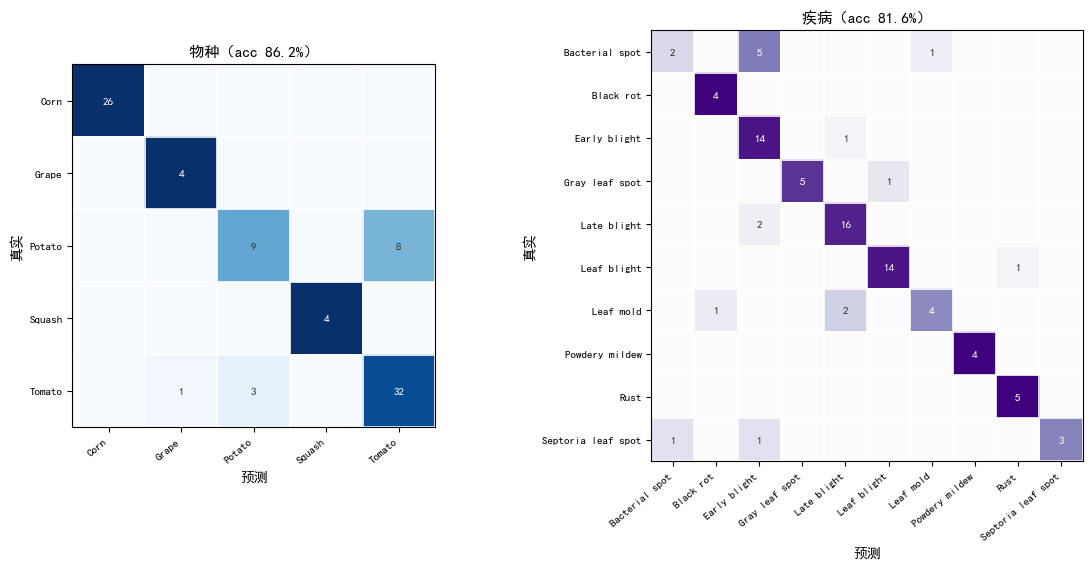

In [12]:
payload = torch.load(CLS_CKPT, map_location=DEVICE)
species_names = payload["species_names"]
disease_names = payload["disease_names"]
species_to_diseases = payload["species_to_diseases"]
disease_to_idx = {name: i for i, name in enumerate(disease_names)}

eval_model = LeafClassifier(
    payload["backbone"], len(species_names), len(disease_names),
    hidden=payload["hidden"], dropout=payload["dropout"],
    unfreeze_blocks=payload["unfreeze_blocks"],
).to(DEVICE)
eval_model.load_state_dict(payload["state_dict"])
eval_model.eval()
print(f"载入 {CLS_CKPT.name} | {payload['backbone']} @ {payload['img_size']}px | "
      f"放开 {payload['unfreeze_blocks']} 个 block | TTA {payload['tta']}")

species_true, species_pred, disease_true, disease_pred = [], [], [], []
with torch.no_grad():
    for images, species, diseases in cls_loaders["test"]:
        images = images.to(DEVICE)
        with torch.cuda.amp.autocast(enabled=DEVICE.type == "cuda"):
            logits_species, logits_disease = eval_model(images)
            if payload["tta"]:
                flip_species, flip_disease = eval_model(torch.flip(images, dims=[3]))
                logits_species = (logits_species + flip_species) / 2
                logits_disease = (logits_disease + flip_disease) / 2
        prob_species = F.softmax(logits_species.float(), dim=1).cpu().numpy()
        prob_disease = F.softmax(logits_disease.float(), dim=1).cpu().numpy()
        for index in range(images.size(0)):
            s_hat = int(prob_species[index].argmax())
            allowed = [disease_to_idx[name] for name in species_to_diseases[species_names[s_hat]]]
            masked = prob_disease[index].copy()
            masked[[i for i in range(len(disease_names)) if i not in allowed]] = 0
            species_true.append(int(species[index]))
            species_pred.append(s_hat)
            disease_true.append(int(diseases[index]))
            disease_pred.append(int(masked.argmax()))

species_true = np.asarray(species_true)
species_pred = np.asarray(species_pred)
disease_true = np.asarray(disease_true)
disease_pred = np.asarray(disease_pred)

species_acc = float((species_true == species_pred).mean())
disease_acc = float((disease_true == disease_pred).mean())
joint_acc = float(((species_true == species_pred) & (disease_true == disease_pred)).mean())
print(f"物种准确率 {species_acc:.4f} ({int(species_acc * len(species_true))}/{len(species_true)}) | "
      f"疾病准确率 {disease_acc:.4f} | 联合 {joint_acc:.4f}")
print(classification_report(disease_true, disease_pred, labels=list(range(len(disease_names))),
                            target_names=disease_names, zero_division=0))


def draw_confusion(ax, y_true, y_pred, names, title, cmap):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(names))))
    norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    ax.imshow(norm, cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
    ax.set_xticklabels(names, rotation=40, ha="right", fontsize=8)
    ax.set_yticklabels(names, fontsize=8)
    ax.set_xticks(np.arange(-0.5, len(names), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(names), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.2)
    ax.tick_params(which="minor", length=0)
    ax.set_xlabel("预测"); ax.set_ylabel("真实")
    ax.set_title(f"{title}（acc {float((np.asarray(y_true) == np.asarray(y_pred)).mean()):.1%}）",
                 fontsize=11)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                        color="white" if norm[i, j] > 0.55 else "#333")


fig = plt.figure(figsize=(14, 5.6))
grid = fig.add_gridspec(1, 2, width_ratios=[1, 1.6], wspace=0.3)
draw_confusion(fig.add_subplot(grid[0, 0]), species_true, species_pred, species_names, "物种", "Blues")
draw_confusion(fig.add_subplot(grid[0, 1]), disease_true, disease_pred, disease_names, "疾病", "Purples")
plt.show()

## 11. 联合推理（分割 + 分类）

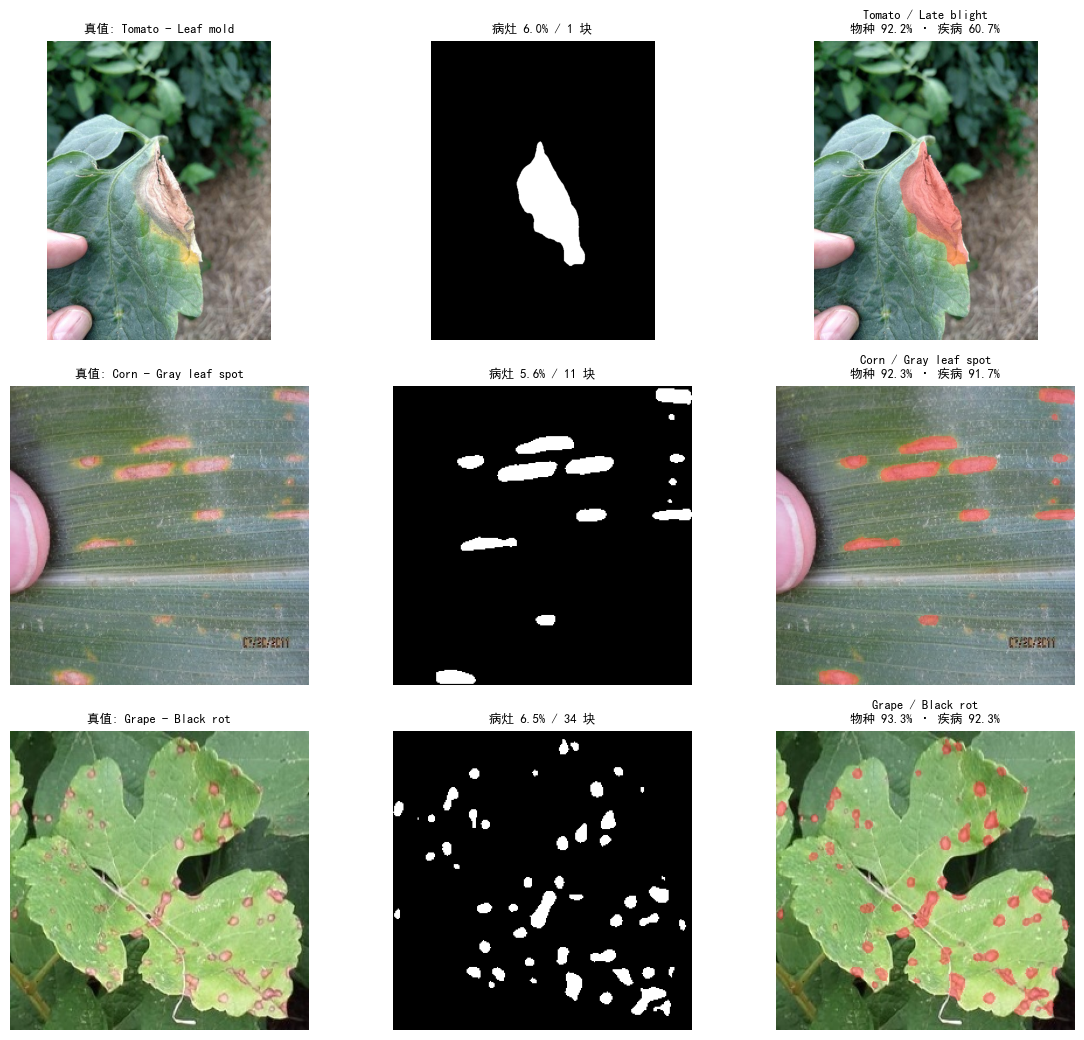

分割权重: D:\WorkSpace2\plants-intelligent-system\models\leaf_disease_segment_model.pth
分类权重: D:\WorkSpace2\plants-intelligent-system\models\leaf_disease_classify_model.pth （vit_small_patch14_dinov2.lvd142m 微调最后 4 个 block，TTA True）


In [13]:
def segment(image):
    """整图 → 病灶 mask（原图尺寸）。"""
    tensor = SEG_EVAL_TF(image=image)["image"].unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        prob = torch.sigmoid(seg_model(tensor)).cpu().numpy().squeeze()
    prob = cv2.resize(prob, (image.shape[1], image.shape[0]))
    binary = (prob > 0.5).astype(np.uint8)
    count, _, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    lesions = [stats[i, cv2.CC_STAT_AREA] for i in range(1, count) if stats[i, cv2.CC_STAT_AREA] >= 48]
    return binary, len(lesions), float(binary.mean() * 100)


# 下面用到 eval_model / disease_to_idx / payload，都来自 §10，跑之前先执行 cell 20
INFER_TTA = bool(payload.get("tta", True))


@torch.no_grad()
def classify(image):
    """整图 → 物种/疾病（预处理和 TTA 跟 §10 测试集完全一致）。"""
    tensor = cls_eval_tf(Image.fromarray(image)).unsqueeze(0).to(DEVICE)
    logits_species, logits_disease = eval_model(tensor)
    if INFER_TTA:
        flip_species, flip_disease = eval_model(torch.flip(tensor, dims=[3]))
        logits_species = (logits_species + flip_species) / 2
        logits_disease = (logits_disease + flip_disease) / 2
    prob_species = F.softmax(logits_species.float(), dim=1)[0].cpu().numpy()
    prob_disease = F.softmax(logits_disease.float(), dim=1)[0].cpu().numpy()

    s_hat = int(prob_species.argmax())
    allowed = [disease_to_idx[name] for name in species_to_diseases[species_names[s_hat]]]
    masked = prob_disease.copy()
    masked[[j for j in range(len(disease_names)) if j not in allowed]] = 0
    d_hat = int(masked.argmax())
    return {"species": species_names[s_hat], "species_conf": float(prob_species[s_hat]),
            "disease": disease_names[d_hat], "disease_conf": float(prob_disease[d_hat])}


demo = cls_df[cls_df["split"] == "test"].sample(3, random_state=SEED)
fig, axes = plt.subplots(len(demo), 3, figsize=(12, 3.5 * len(demo)))
axes = np.atleast_2d(axes)

for row, (_, item) in enumerate(demo.iterrows()):
    image = cv2.cvtColor(cv2.imread(item["path"]), cv2.COLOR_BGR2RGB)
    binary, lesion_count, lesion_ratio = segment(image)
    result = classify(image)

    overlay = image.copy()
    overlay[binary > 0] = [255, 66, 66]
    overlay = cv2.addWeighted(image, 0.6, overlay, 0.4, 0)

    axes[row, 0].imshow(image); axes[row, 0].set_title(f'真值: {item["label"]}', fontsize=9)
    axes[row, 1].imshow(binary, cmap="gray")
    axes[row, 1].set_title(f"病灶 {lesion_ratio:.1f}% / {lesion_count} 块", fontsize=9)
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(f'{result["species"]} / {result["disease"]}\n'
                           f'物种 {result["species_conf"]:.1%} · 疾病 {result["disease_conf"]:.1%}',
                           fontsize=9)
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("分割权重:", SEG_CKPT)
print("分类权重:", CLS_CKPT,
      f"（{payload['backbone']} 微调最后 {payload['unfreeze_blocks']} 个 block，TTA {INFER_TTA}）")
